<a href="https://colab.research.google.com/github/Hema392/ITA0314-Mobile-Computing-/blob/main/Exp19.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


EXPERIMENT 19: HANDOFF SIMULATION

H(dB)   Handoffs   Ping-pongs
0 35 34
2 27 26
4 11 10
6 7 6
8 3 2
10 1 0

Handoff events at H=6 dB: [(1010.0, '1->2'), (1015.0, '2->1'), (1045.0, '1->2'), (1060.0, '2->1'), (1070.0, '1->2'), (1095.0, '2->1'), (1105.0, '1->2')]


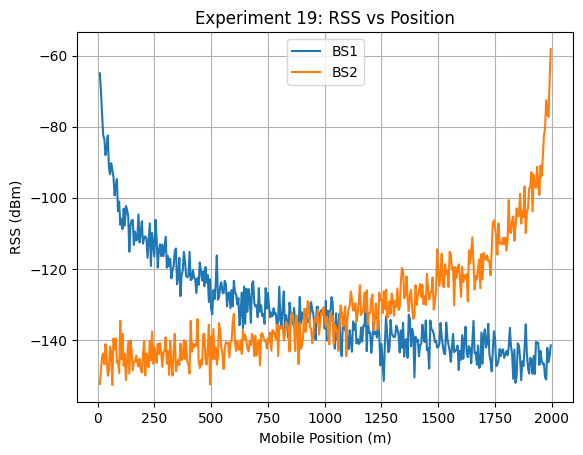

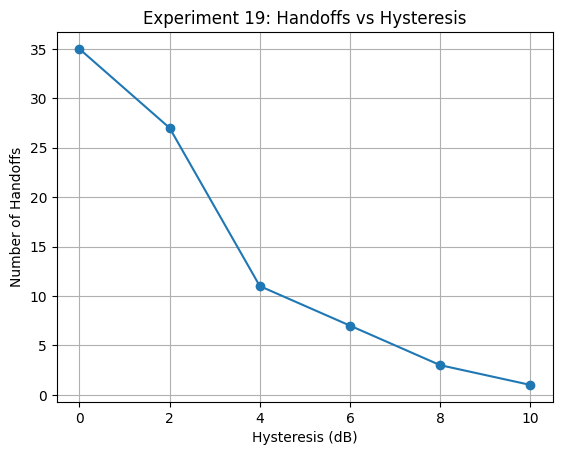


EXPERIMENT 20: CDMA

User 1 Data: [1, 0, 1, 1]
User 1 Spread: [ 1 -1  1 -1 -1  1 -1  1  1 -1  1 -1  1 -1  1 -1]

User 2 Data: [0, 0, 1, 0]
User 2 Spread: [-1 -1  1  1 -1 -1  1  1  1  1 -1 -1 -1 -1  1  1]

User 3 Data: [1, 1, 0, 1]
User 3 Spread: [ 1 -1 -1  1  1 -1 -1  1 -1  1  1 -1  1 -1 -1  1]

Composite Signal:
[ 1 -3  1  1 -1 -1 -1  3  1  1  1 -3  1 -3  1  1]

Despreading Results:
User 1 Correlator: [ 1. -1.  1.  1.]
Recovered Data: [1, 0, 1, 1]
Status: OK
User 2 Correlator: [-1. -1.  1. -1.]
Recovered Data: [0, 0, 1, 0]
Status: OK
User 3 Correlator: [ 1.  1. -1.  1.]
Recovered Data: [1, 1, 0, 1]
Status: OK


Text(0, 0.5, 'Amplitude')

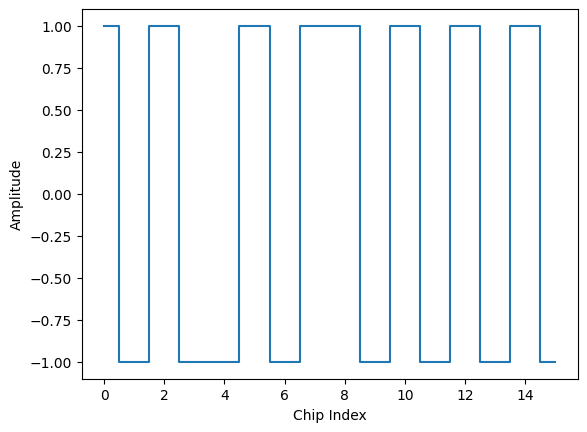

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math
print("\nEXPERIMENT 19: HANDOFF SIMULATION")

rng = np.random.default_rng(7)

D = 2000.0
P0, n, sigma = -30.0, 3.5, 4.0

x = np.arange(10, D, 5.0)

def rss(d, shadow):
    return P0 - 10*n*np.log10(d) + shadow

r1 = rss(x, rng.normal(0, sigma, x.size))
r2 = rss(D-x, rng.normal(0, sigma, x.size))

def run(H):
    serving = 1
    handoffs = 0
    log = []

    for xi, a, b in zip(x, r1, r2):
        if serving == 1 and b > a + H:
            serving = 2
            handoffs += 1
            log.append((float(xi), '1->2'))

        elif serving == 2 and a > b + H:
            serving = 1
            handoffs += 1
            log.append((float(xi), '2->1'))

    return handoffs, log

H_values = [0, 2, 4, 6, 8, 10]
counts = []

print("\nH(dB)   Handoffs   Ping-pongs")

for H in H_values:
    h, log = run(H)
    counts.append(h)
    print(H, h, max(h-1,0))

h, log = run(6)
print("\nHandoff events at H=6 dB:", log)

plt.figure()
plt.plot(x, r1, label="BS1")
plt.plot(x, r2, label="BS2")
plt.xlabel("Mobile Position (m)")
plt.ylabel("RSS (dBm)")
plt.title("Experiment 19: RSS vs Position")
plt.legend()
plt.grid()
plt.show()

plt.figure()
plt.plot(H_values, counts, marker='o')
plt.xlabel("Hysteresis (dB)")
plt.ylabel("Number of Handoffs")
plt.title("Experiment 19: Handoffs vs Hysteresis")
plt.grid()
plt.show()


# ==========================================
# EXPERIMENT 20: CDMA SPREADING AND DESPREADING
# ==========================================

print("\nEXPERIMENT 20: CDMA")

W = np.array([
    [1, 1, 1, 1],
    [1,-1, 1,-1],
    [1, 1,-1,-1],
    [1,-1,-1, 1]
])

bits = {
    1: [1,0,1,1],
    2: [0,0,1,0],
    3: [1,1,0,1]
}

L = 4
nbits = 4

def bpsk(b):
    return 2*np.array(b)-1

tx = np.zeros(nbits*L)
spread_signals = {}

for u,b in bits.items():
    spread = np.repeat(bpsk(b),L) * np.tile(W[u],nbits)

    spread_signals[u] = spread
    print("\nUser",u,"Data:",b)
    print("User",u,"Spread:",spread.astype(int))

    tx += spread

print("\nComposite Signal:")
print(tx.astype(int))

correlators = {}

print("\nDespreading Results:")

for u,b in bits.items():
    corr = (tx*np.tile(W[u],nbits)).reshape(nbits,L).sum(axis=1)/L

    rec = (corr>0).astype(int)
    correlators[u] = corr

    print("User",u,"Correlator:",corr)
    print("Recovered Data:",rec.tolist())
    print("Status:", "OK" if rec.tolist()==b else "ERROR")

plt.figure()
plt.step(range(len(spread_signals[1])),
         spread_signals[1], where='mid')
plt.xlabel("Chip Index")
plt.ylabel("Amplitude")